## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

In [12]:
# Q1 Code moved to Phase 1 solution cell below.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

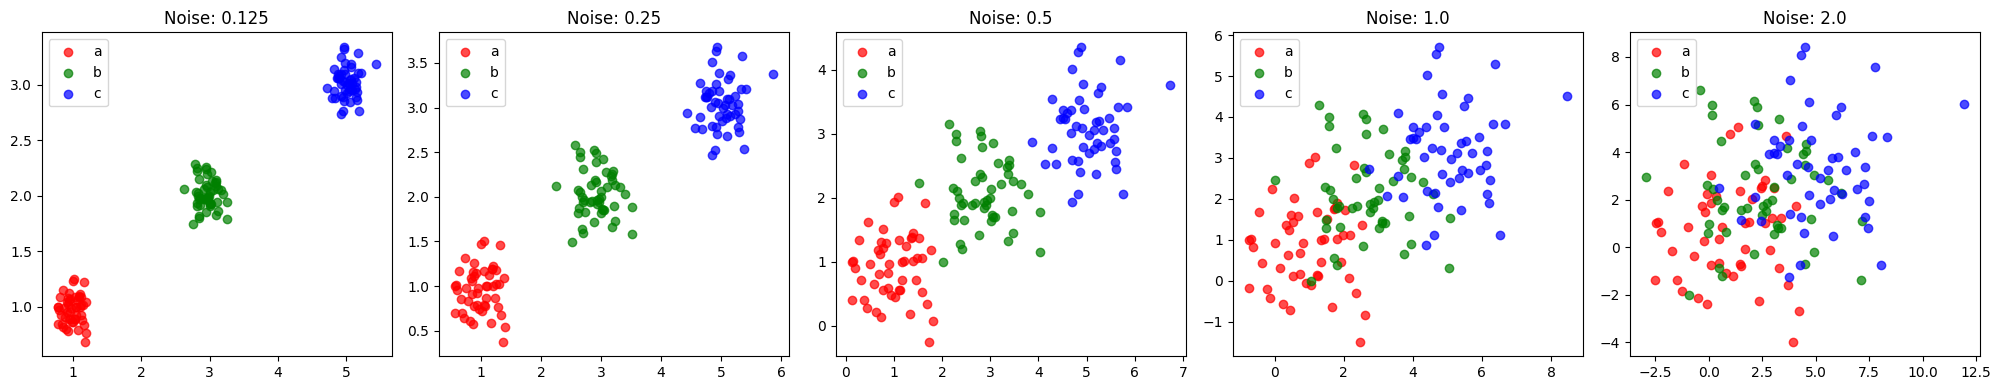

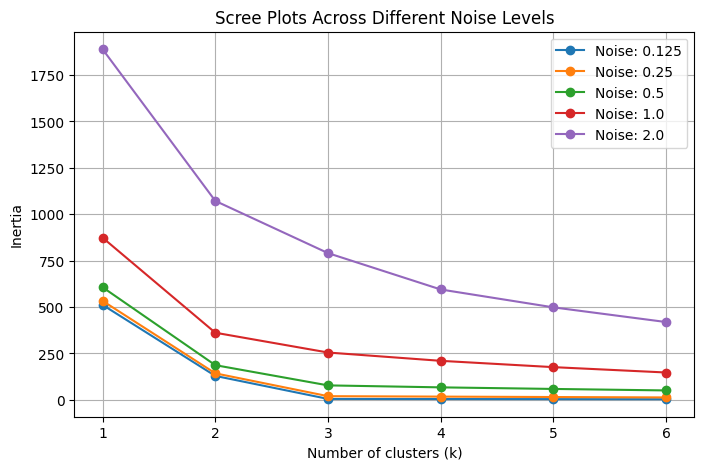

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# Q1.1: Provided Data Generation Function
def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0)

datasets = {
    '0.125': createData(0.125),
    '0.25': createData(0.25),
    '0.5': createData(0.5),
    '1.0': createData(1.0),
    '2.0': createData(2.0)
}

# Q1.2: Scatterplots by group
# as noise increases from 0.125 to 2.0, visual distinctness degrades dramatically.
# At low noise (0.125), clusters 'a', 'b', and 'c' are perfectly isolated. At high noise (2.0),
# they completely overlap into a single indistinguishable cloud of points.
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (noise_val, df) in zip(axes, datasets.items()):
    for group, color in zip(['a', 'b', 'c'], ['red', 'green', 'blue']):
        subset = df[df['group'] == group]
        ax.scatter(subset['x1'], subset['x2'], label=group, alpha=0.7, c=color)
    ax.set_title(f"Noise: {noise_val}")
    ax.legend()
plt.tight_layout()
plt.show()

# Q1.3: Scree plots (Inertia vs. k for each dataset)
# low noise produces a very sharp "elbow" at k=3 because any cluster split beyond that
# yields negligible reduction in within-cluster variance. High noise raises the absolute
# inertia values and flattens out the curve, making it hard to find a definitive k.
fig, ax = plt.subplots(figsize=(8, 5))
k_values = range(1, 7)

for noise_val, df in datasets.items():
    X = df[['x1', 'x2']]
    inertias = []
    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=100, n_init=10).fit(X)
        inertias.append(kmeans.inertia_)
    ax.plot(k_values, inertias, marker='o', label=f"Noise: {noise_val}")

ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
ax.set_title("Scree Plots Across Different Noise Levels")
ax.legend()
plt.grid(True)
plt.show()

# Q1.4: Elbow Intuition
# the "elbow" represents the point of diminishing returns. Adding more clusters up to
# the true number of sub-populations (k=3) drastically drops inertia because we group distinct
# generative centers. Adding more clusters beyond k=3 merely partitions homogeneous groups,
# resulting in minor, linear decreases in inertia.

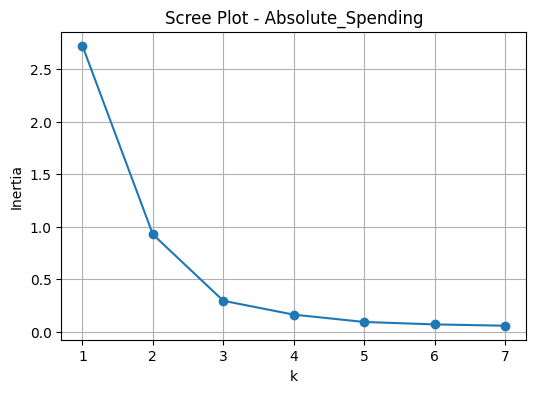

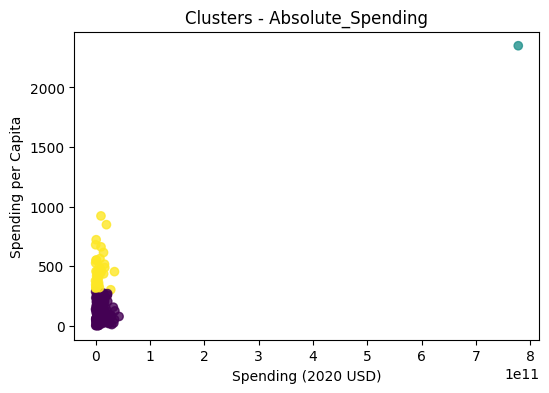


--- Describe Table: Absolute_Spending ---


Spending (2020 USD)                              \
                                        count          mean           std   
cluster_Absolute_Spending                                                   
0                                       111.0  9.975941e+09  9.511248e+09   
1                                         1.0  7.780000e+11           NaN   
2                                        36.0  7.400556e+09  8.084250e+09   

                                                                     \
                                    min           25%           50%   
cluster_Absolute_Spending                                             
0                          6.976409e+07  3.033109e+09  6.876593e+09   
1                          7.780000e+11  7.780000e+11  7.780000e+11   
2                          5.537420e+07  1.265478e+09  4.844831e+09   

                                                      Spending per Capita  \
                                    75%           max               count   
cluster_Absolute_Spending                                                   
0                          1.477349e+10  4.334146e+10               111.0   
1                          7.780000e+11  7.780000e+11                 1.0   
2                          1.005553e+10  3.492807e+10                36.0   

                                                                              \
                                  mean         std          min          25%   
cluster_Absolute_Spending                                                      
0                           117.431776   82.437628     1.014887    47.116476   
1                          2350.000000         NaN  2350.000000  2350.000000   
2                           475.757310  147.113764   302.712438   373.975651   

                                                                  
                                   50%          75%          max  
cluster_Absolute_Spending                                         
0                            94.187358   195.186510   286.777525  
1                          2350.000000  2350.000000  2350.000000  
2                           450.015256   532.893192   922.113950

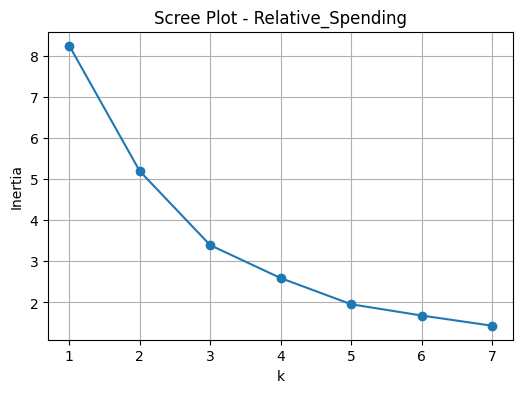

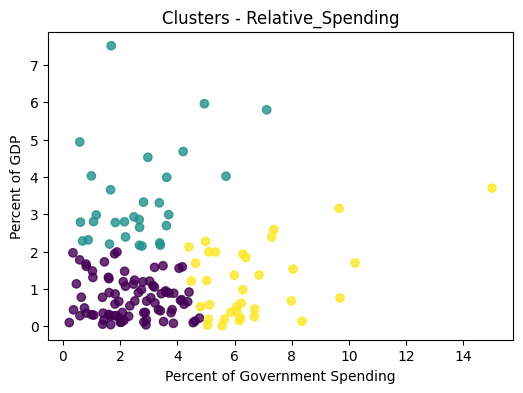


--- Describe Table: Relative_Spending ---


Percent of Government Spending                      \
                                                   count      mean       std   
cluster_Relative_Spending                                                      
0                                                   83.0  2.413304  1.195459   
1                                                   30.0  2.642196  1.538601   
2                                                   35.0  6.591065  2.079275   

                                                                              \
                                min       25%       50%       75%        max   
cluster_Relative_Spending                                                      
0                          0.221398  1.594427  2.296395  3.372628   4.771337   
1                          0.588317  1.637872  2.670281  3.399293   7.121785   
2                          4.404631  5.111288  6.167185  7.074622  15.000000   

                          Percent of GDP                                \
                                   count      mean       std       min   
cluster_Relative_Spending                                                
0                                   83.0  0.752493  0.541828  0.034219   
1                                   30.0  3.396668  1.312799  2.146173   
2                                   35.0  1.174185  0.958561  0.011626   

                                                                   
                                25%       50%       75%       max  
cluster_Relative_Spending                                          
0                          0.289882  0.670391  1.130125  1.988304  
1                          2.455164  2.892436  4.012380  7.515523  
2                          0.383503  0.976701  1.886023  3.700000

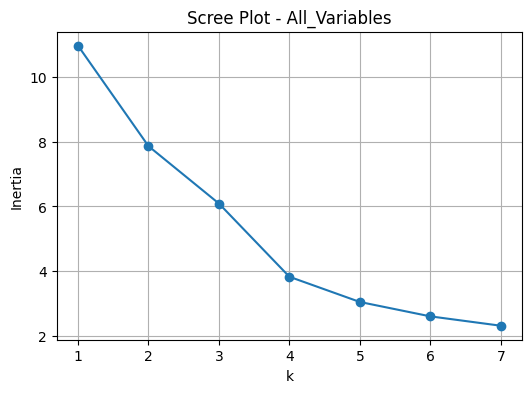

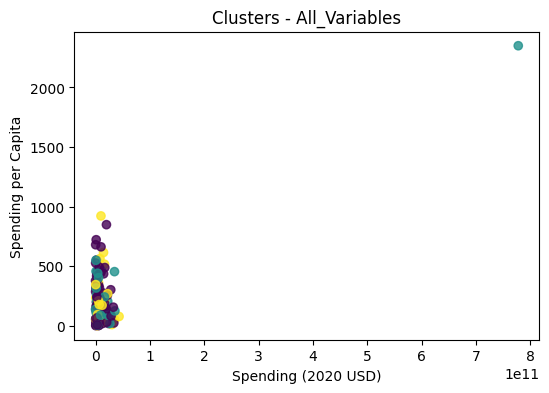


--- Describe Table: All_Variables ---


Spending (2020 USD)                              \
                                    count          mean           std   
cluster_All_Variables                                                   
0                                    82.0  8.168742e+09  8.333598e+09   
1                                    35.0  3.303446e+10  1.300002e+11   
2                                    31.0  1.050666e+10  1.036859e+10   

                                                                               \
                                min           25%           50%           75%   
cluster_All_Variables                                                           
0                      5.537420e+07  1.903907e+09  4.541259e+09  1.291529e+10   
1                      6.976409e+07  3.438667e+09  9.110544e+09  1.561281e+10   
2                      3.758448e+08  3.754716e+09  6.876593e+09  1.441320e+10   

                                    Spending per Capita              ...  \
                                max               count        mean  ...   
cluster_All_Variables                                                ...   
0                      3.370630e+10                82.0  209.655854  ...   
1                      7.780000e+11                35.0  240.819509  ...   
2                      4.334146e+10                31.0  222.313787  ...   

                      Percent of Government Spending             \
                                                 75%        max   
cluster_All_Variables                                             
0                                           3.308337   4.616023   
1                                           7.074622  15.000000   
2                                           3.510575   7.121785   

                      Percent of GDP                                          \
                               count      mean       std       min       25%   
cluster_All_Variables                                                          
0                               82.0  0.759035  0.541853  0.034219  0.298366   
1                               35.0  1.119642  0.957179  0.011626  0.313581   
2                               31.0  3.355647  1.310785  2.125000  2.351492   

                                                     
                            50%       75%       max  
cluster_All_Variables                                
0                      0.673494  1.131952  1.988304  
1                      0.752346  1.766217  3.700000  
2                      2.855213  4.004997  7.515523  

[3 rows x 32 columns]

           Country  cluster_Absolute_Spending  cluster_Relative_Spending  \
147  United States                          1                          2   

     cluster_All_Variables  
147                      1  


In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import os

# Q2.1: Load, Clean, and Check for Further Cleaning
# no further cleaning is strictly required after filtering and dropping NaNs,
# though feature scaling is necessary before distance-based clustering.
filepath = "SIPRI Military Expenditure Database.csv"
if not os.path.exists(filepath):
    filepath = "data/SIPRI Military Expenditure Database.csv"



# Helper function to run pipeline: Normalize -> Scree Plot -> KMeans -> Scatter -> Describe
def analyze_clustering(data, feature_cols, title_suffix):
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(data[feature_cols])

    # Scree plot to determine optimal k
    k_values = range(1, 8)
    inertias = []
    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=100, n_init=10).fit(X_scaled)
        inertias.append(kmeans.inertia_)

    plt.figure(figsize=(6, 4))
    plt.plot(k_values, inertias, marker="o")
    plt.title(f"Scree Plot - {title_suffix}")
    plt.xlabel("k")
    plt.ylabel("Inertia")
    plt.grid(True)
    plt.show()

    # Optimal k selection
    optimal_k = 3
    kmeans = KMeans(n_clusters=optimal_k, random_state=100, n_init=10).fit(X_scaled)
    data[f"cluster_{title_suffix}"] = kmeans.labels_

    # Scatterplot of the first two features
    plt.figure(figsize=(6, 4))
    plt.scatter(
        data[feature_cols[0]],
        data[feature_cols[1]],
        c=data[f"cluster_{title_suffix}"],
        cmap="viridis",
        alpha=0.8,
    )
    plt.xlabel(feature_cols[0])
    plt.ylabel(feature_cols[1])
    plt.title(f"Clusters - {title_suffix}")
    plt.show()

    # Conditional Describe Table
    desc = data.groupby(f"cluster_{title_suffix}")[feature_cols].describe()
    print(f"\n--- Describe Table: {title_suffix} ---")
    display(desc)

    return data

# Q2.2: Spending (USD) and Spending per Capita
# highly skewed distributions. The US sits in an isolated cluster of 1 (or very few)
# due to its extreme total absolute spending compared to all other nations.
df_2020 = analyze_clustering(df_2020, cols_p2, "Absolute_Spending")

# Q2.3: Percentages
# comparing percentages focuses on domestic priorities. Countries with high
# militarization (like Middle Eastern nations) stand out here, grouping differently than in Part 2.
df_2020 = analyze_clustering(df_2020, cols_p3, "Relative_Spending")

# Q2.4: All Four Variables Combined
# combining both scales integrates raw power metrics (USD) and budget share
# priorities, creating robust, multi-dimensional profiles.
df_2020 = analyze_clustering(df_2020, all_vars, "All_Variables")

# Q2.5: Utility of k-Means Clustering
#  k-MC successfully identifies outliers (like the US) and characterizes profiles,
# distinguishing global spenders from domestically defense-focused nations.
if "Country" in df_2020.columns:
    print(df_2020[df_2020["Country"].str.contains("United States", na=False)][
        ["Country", "cluster_Absolute_Spending", "cluster_Relative_Spending", "cluster_All_Variables"]
    ])

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [15]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]